# Jev-as-a-Judge, LLM-as-a-Judge, and confidence-based escalation

A routing agent predicts an intent. A **judge evaluates that prediction**. In this lab the
judge answers the existing notebook's focused question: **did the router misclassify the
request specifically because the user's utterance was vague?** `TRUE` means that failure
occurred; `FALSE` includes both correct routing and errors caused by something else.

We compare three policies on the same human-labeled traces:

1. Jev alone as the judge.
2. GPT-4.1-mini alone as an independent judge.
3. Jev first, with uncertain or invalid judgments sent to GPT-4.1-mini.

**Replay** recomputes results from a recorded run without a key or new charges. **Live**
mode calls TypeSafe directly for Jev and a separately authenticated provider for the LLM,
then caches the responses. The notebook selects replay when a
recorded manifest is present, otherwise live. Run every cell in order.

**Benchmark complete:** 300 real TypeSafe judgments and 300 independent OpenAI judgments
are recorded. Replay needs no credentials. The 0.70 calibration-selected gate escalates
39/200 held-out traces. Temporary synthetic fixtures are only used in tests.
The results below show a cost/recall tradeoff, not a universal improvement in judge quality.
This notebook evaluates logs; it does not make calendar changes.

Inspired by the [clinic Jev/GPT notebook](https://colab.research.google.com/drive/1FtSQhtAx8rlkWlV7GA87kIcaHwHG_mL_).
That notebook classifies intents; this one measures agreement with human **judge labels**.

## 1. Why bring System 1 thinking to evaluation?

The System 1 / System 2 analogy separates a quick, narrow judgment from more deliberative
reasoning. Jev applies the first idea to software: it returns a typed decision and
probabilities for a question defined by your policy. An LLM can additionally produce a short
explanation, useful when the case needs closer inspection. These are design roles, not a
claim that either model reproduces human cognition or that the LLM always wins.

A repeated, well-defined check is a useful candidate for a cheap first pass. The hypothesis
we will test is that Jev can handle many cases, while an LLM earns its extra cost on the cases
Jev finds uncertain. Whether that works depends on **error detection, complementary
judgments, and measured costs**. Confidence can be high on an incorrect answer.

See [TypeSafe's System One introduction](https://docs.typesafe.ai/introduction).

In [1]:
# Run from this directory, the repository root, or a fresh Colab runtime.
import os, sys, subprocess
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_REF = os.environ.get("ROUTING_EVALS_REF", "codex/jev-routing-judge")
candidates = [Path.cwd(), Path.cwd() / "routing_agent_evals",
              Path.cwd() / "AI-Evals-Principles/routing_agent_evals"]
LAB = next((p for p in candidates if (p / "judge_lab.py").exists()), None)
if LAB is None and IN_COLAB:
    checkout = Path("/content/routing-evals-lab")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_REF,
                        "https://github.com/The-Gen-Academy/Mastering-Agentic-AI-Week4-Session1.git",
                        str(checkout)], check=True)
    LAB = checkout / "AI-Evals-Principles/routing_agent_evals"
if LAB is None or not (LAB / "judge_lab.py").exists():
    raise RuntimeError("Open the notebook from its repository checkout; see README for setup.")
LAB = LAB.resolve()
os.chdir(LAB)
sys.path.insert(0, str(LAB))
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pandas", "scikit-learn", "matplotlib", "python-dotenv"], check=True)

In [2]:
# Choose replay for a complete recorded run, or live for your own experiment.
EVIDENCE = Path(os.environ.get("JUDGE_EVIDENCE_DIR", str(LAB / "data/jev_judge_run")))
DEFAULT_MODE = "replay" if (EVIDENCE / "manifest.json").exists() else "live"
MODE = os.environ.get("JUDGE_MODE", DEFAULT_MODE)
assert MODE in {"replay", "live"}
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dotenv import load_dotenv
from judge_lab import (JudgeClient, batch, load_dataset, split_dataset, request_for,
                       metrics, select_threshold, run_cascade, needs_llm,
                       confidence_bands, always_false, save_json, digest,
                       POLICY, CRITERIA, JEV_MODEL, LLM_MODEL, DEFAULT_PROVIDERS)

load_dotenv(LAB / ".env", override=False)
RUN = Path(os.environ.get("JUDGE_RUN_DIR", str(LAB / ".runs/judge")))
RUN.mkdir(parents=True, exist_ok=True)
CACHE = EVIDENCE / "cache" if MODE == "replay" else RUN / "cache"
if MODE == "replay" and not (EVIDENCE / "manifest.json").exists():
    raise RuntimeError("No complete benchmark here. Run live with funded judge credentials, then replay that run directory.")
manifest = json.loads((EVIDENCE / "manifest.json").read_text()) if MODE == "replay" else {}
providers = manifest.get("providers", DEFAULT_PROVIDERS) if MODE == "replay" else {
    "jev": os.environ.get("JEV_PROVIDER", "typesafe"),  # or "openrouter"
    "llm": os.environ.get("LLM_PROVIDER", "openai"),  # or "openrouter"
}
client = JudgeClient(CACHE, live=(MODE == "live"), providers=providers,
                     models=manifest.get("models"), pricing=manifest.get("pricing"))
if MODE == "live":
    secrets_by_name = {}
    for stage, name in client.key_names.items():
        key = secrets_by_name.get(name) or os.environ.get(name)
        if not key and IN_COLAB:
            try:
                from google.colab import userdata
                key = userdata.get(name)
            except Exception:
                pass
        if not key:
            from getpass import getpass
            key = getpass(f"{name} (hidden, never saved): ").strip()
        secrets_by_name[name] = key
        client.api_keys[stage] = key
print("Mode:", MODE, "| providers:", client.providers, "| models:", client.models)
print("HTTP 401/402/403 stops the run. Fix that provider's credentials/credits, then resume.")

Mode: replay | providers: {'jev': 'typesafe', 'llm': 'openai'} | models: {'jev': 'jev-1.13.0', 'llm': 'gpt-4.1-mini-2025-04-14'}
HTTP 401/402/403 stops the run. Fix that provider's credentials/credits, then resume.


## 2. Freeze the task, inputs and references

Both judges receive the same original intent definitions, vague-failure policy,
`USER_INPUT`, and the router's `final_intent`. The LLM does not see Jev's label or confidence.
Neither judge sees `TARGET_INTENT`, human comments, failure categories, or the human
`Vague_Utterance_Failure` label. Those fields would leak the answer.

The CSV contains 300 judge labels: 20 `TRUE` and 280 `FALSE`. A constant `FALSE` judge
therefore has 93.3% accuracy and zero failure recall. We report positive-class precision,
recall and F1, confusion counts, and unresolved outputs alongside accuracy.

The source files have historical inconsistencies. We preserve the explicit judge labels
and report **agreement with those labels**, not universal correctness. Cross-file intent
differences and a query mismatch are shown below. The legacy `intent_match` field contains
prose on many rows; we do not use it to derive the human judge label.

In [3]:
rows = load_dataset(LAB / "data")
calibration, heldout = split_dataset(rows)
assert set(r["id"] for r in calibration).isdisjoint(r["id"] for r in heldout)
display(pd.DataFrame([{"split": name, "rows": len(part),
                       "TRUE labels": sum(r["human_label"] == "TRUE" for r in part)}
                      for name, part in [("Full dataset", rows), ("Calibration", calibration),
                                         ("Held out", heldout)]]))
audit = pd.DataFrame([{"ID": r["id"], "issue": issue}
                      for r in rows for issue in r["reference_issues"]])
display(audit.groupby("issue").size().rename("rows").to_frame())
audit.to_csv(RUN / "reference-audit.csv", index=False)
display(pd.DataFrame(rows[:3])[["id", "user_query", "predicted_intent", "human_label"]])
print("Dataset SHA-256:", digest(rows))

,split,rows,TRUE labels
0,Full dataset,300,20
1,Calibration,100,7
2,Held out,200,13


,rows
issue,
legacy_intent_match_contains_prose,248
query_differs_between_csvs,1
target_differs_between_csvs,10


,id,user_query,predicted_intent,human_label
0,TEST_009,How many patients did I see last month?,IRRELEVANT_QUERY,FALSE
1,TEST_016,Cancel my 10:00 - 10:30 patient Monday,UNSUPPORTED_REQUEST,FALSE
2,TEST_031,I am busy today,UNSUPPORTED_REQUEST,TRUE


Dataset SHA-256: c5f9c5d5989767cd69b2d39ba7651457f670792bbfc9097bed62069170e4a8f1


We reserve roughly one third of the examples for calibration and the rest for a final
held-out comparison. The split is deterministic, stratified by the human Boolean label,
and groups identical normalized queries together. Human labels balance the split; they
never enter an API request. We freeze the prompt before these calls and select the gate
using calibration data only.

In [4]:
print("Shared policy:\n", POLICY)
display(pd.DataFrame([{"decision": label, "definition": text} for label, text in CRITERIA.items()]))
sample_request = request_for(rows[0], "jev")
print("State sent to Jev:", sample_request["state"])
assert set(sample_request["state"]) == {"user_query", "predicted_intent"}

Shared policy:
 # Role:
You are an impartial evaluator for an AI scheduling assistant used by doctors.

#Goal:
Your job is to determine whether a misclassification of intent occurred specifically due to “vague utterances.” wherein the request is ambiguous and/or missing key arguments.

# What you will be given
- A chat trace between the doctor (user) and the agent
- The agent’s predicted intent for the doctor’s request (the “model intent”)
- The set of valid intents with definitions (provided below)

# Your task:
1. Identify the  request the agent should act on.
2. Determine the most appropriate gold intent for that request using the intent definitions.
3. Decide whether the agent’s intent classification is wrong.
4. If wrong, decide whether the error is caused by a “vague utterance” (as defined below), versus other causes 

# Definition of “Vague utterances” failure mode

Mark VAGUE_UTTERANCE = True only when:
- User intent could be supported but is ambiguous or missing key arguments,

,decision,definition
0,TRUE,The predicted intent is wrong specifically bec...
1,FALSE,"The predicted intent is correct, or it is wron..."


State sent to Jev: {'user_query': 'How many patients did I see last month?', 'predicted_intent': 'IRRELEVANT_QUERY'}


## 3. Jev alone: a categorical judge

This task uses **`type: "choice"`**, with named `TRUE` / `FALSE` options. Jev returns
`choice`, `probabilities`, and `confidence`. We use its returned label directly. There is
no ordered quality scale, weighted-average `score`, or 1–5 conversion in this lab. A Noul
could represent the same yes/no question; Choice is used here to expose the confidence
field explicitly.

**Probability and confidence differ.** For a two-option Choice, TypeSafe defines
`confidence = 2 × max(probabilities) − 1`. Thus probabilities 0.85 / 0.15 yield confidence
0.70. A confidence of 0.70 does not mean 70% accuracy. We use the returned confidence
and check its relationship with errors on our own data.

[Choice documentation](https://docs.typesafe.ai/primitives/choice) ·
[Confidence definition](https://docs.typesafe.ai/confidence)

In [5]:
jev_cal = batch(calibration, lambda r: client.call(r, "jev"))
example = calibration[0]
display(pd.DataFrame([jev_cal[example["id"]]]))
display(pd.DataFrame([metrics(calibration, jev_cal, "Jev alone — calibration")]))

,id,stage,request_hash,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,attempts,elapsed_seconds,input_tokens,output_tokens,label,error,confidence,probabilities,model
0,TEST_016,jev,376b850973bcd023e1597bbb6ad81b4685e036b530bd60...,0.000056,0,0.000056,1,0,1,1,0.099805,1328,33,FALSE,None,1.0,"{'TRUE': 0.0, 'FALSE': 1.0}",jev-1.13.0


,method,n,positive_references,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,llm_routes
0,Jev alone — calibration,100,7,0.89,0.0,0.0,0,89,4,7,0,0,0.005548,0,0.005548,100,0,100,0


## 4. LLM alone: the independent baseline

GPT-4.1-mini receives the same task and trace, with a JSON schema requiring `label` and a
brief `reason`. Schema validation catches malformed responses; it does not make an answer
correct. Temperature zero reduces sampling variation and does not guarantee repeatability.
The explanation is for inspection, not a promise that asking for reasoning improves accuracy.

This baseline is independent of Jev. The cascade will call **this same judge** on selected
traces, which lets us compare policies without changing the LLM's information or prompt.

In [6]:
llm_cal = batch(calibration, lambda r: client.call(r, "llm"))
display(pd.DataFrame([llm_cal[example["id"]]]))
display(pd.DataFrame([metrics(calibration, values, name) for name, values in
                      [("Always FALSE", always_false(calibration)),
                       ("Jev alone", jev_cal), ("LLM alone", llm_cal)]]))

,id,stage,request_hash,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,attempts,elapsed_seconds,input_tokens,output_tokens,label,error,reason,model
0,TEST_016,llm,8808bdf6868d0913e9cb6f4a8050ef09d0c1454865f4bb...,0.000524,0,0.000524,1,0,1,1,1.645007,1045,66,FALSE,None,The user's request is to cancel a specific pat...,gpt-4.1-mini-2025-04-14


,method,n,positive_references,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,llm_routes
0,Always FALSE,100,7,0.93,0.000000,0.000000,0.00000,93,0,7,0,0,0.000000,0,0.000000,0,0,0,0
1,Jev alone,100,7,0.89,0.000000,0.000000,0.00000,89,4,7,0,0,0.005548,0,0.005548,100,0,100,0
2,LLM alone,100,7,0.77,0.192308,0.714286,0.30303,72,21,2,5,0,0.050944,0,0.050944,100,0,100,0


## 5. Choose the gate on calibration data

Proposed policy: keep a valid Jev judgment when **confidence ≥ threshold**; otherwise ask
the LLM. Invalid Jev output also escalates. If the LLM fails, the case remains unresolved
for human review; we do not silently replace it with a low-confidence Jev answer.

Before looking at held-out results, we compare thresholds 0, 0.25, 0.50, 0.70, 0.85, 0.95
and 1.00. The predeclared selection rule maximizes **TRUE-class F1**, then accuracy, then
minimizes LLM routes. The final tie goes to the lower threshold. The calibration set has
few positives, so this threshold is a workshop estimate, not a production recommendation.
Even threshold 1 retains valid Jev answers with confidence exactly 1.

In [7]:
threshold, sweep = select_threshold(calibration, jev_cal, llm_cal)
display(pd.DataFrame(sweep)[["threshold", "accuracy", "precision_TRUE", "recall_TRUE",
                             "f1_TRUE", "llm_routes", "cost_usd", "unreported_cost_attempts"]])
print("Locked threshold:", threshold)
save_json(RUN / "calibration.json", {"threshold": threshold, "sweep": sweep,
                                    "ids": [r["id"] for r in calibration]})

,threshold,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,llm_routes,cost_usd,unreported_cost_attempts
0,0.00,0.89,0.000000,0.000000,0.000000,0,0.005548,100
1,0.25,0.90,0.333333,0.428571,0.375000,8,0.009793,108
2,0.50,0.90,0.363636,0.571429,0.444444,11,0.011375,111
3,0.70,0.88,0.333333,0.714286,0.454545,20,0.016045,120
4,0.85,0.86,0.294118,0.714286,0.416667,28,0.020095,128
5,0.95,0.81,0.227273,0.714286,0.344828,48,0.030356,148
6,1.00,0.80,0.217391,0.714286,0.333333,66,0.039414,166


Locked threshold: 0.7


## 6. Run the held-out cascade before the full LLM comparison

The next cell obtains held-out Jev judgments, then invokes the LLM **only** for the
escalated rows. The later LLM-alone benchmark fills in the remaining LLM results, reusing
the escalations already obtained. This separates the proposed deployment path from the
extra calls needed to benchmark it.

In [8]:
jev_test = batch(heldout, lambda r: client.call(r, "jev"))
before_requests = client.new_requests
before_hits = client.cache_hits
cascade_test = run_cascade(heldout, client, threshold, jev=jev_test)
escalated = [r for r in heldout if needs_llm(jev_test[r["id"]], threshold)]
assert sum(r["route"] == "LLM" for r in cascade_test.values()) == len(escalated)
print(f"Escalated {len(escalated)}/{len(heldout)} held-out traces.")
print("Fresh HTTP attempts in gate:", client.new_requests - before_requests,
      "| replay/cache reads:", client.cache_hits - before_hits)
display(pd.DataFrame([metrics(heldout, cascade_test, "Jev then LLM")]))

Escalated 39/200 held-out traces.
Fresh HTTP attempts in gate: 0 | replay/cache reads: 39


,method,n,positive_references,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,llm_routes
0,Jev then LLM,200,13,0.835,0.166667,0.384615,0.232558,162,25,8,5,0,0.031725,0,0.031725,239,0,239,39


In [9]:
llm_test = batch(heldout, lambda r: client.call(r, "llm"))
comparison = pd.DataFrame([metrics(heldout, values, name) for name, values in
                          [("Always FALSE", always_false(heldout)), ("Jev alone", jev_test),
                           ("LLM alone", llm_test), ("Jev then LLM", cascade_test)]])
comparison["cost_per_1000_USD"] = comparison["cost_usd"] / len(heldout) * 1000
comparison["LLM_fraction"] = comparison["llm_routes"] / len(heldout)
display(comparison[["method", "accuracy", "precision_TRUE", "recall_TRUE", "f1_TRUE",
                    "LLM_fraction", "cost_per_1000_USD"]])
display(comparison[["method", "TN", "FP", "FN_including_unresolved", "TP", "unresolved"]])
display(comparison[["method", "reported_cost_usd", "estimated_cost_usd",
                    "estimated_cost_attempts", "unknown_cost_attempts"]])
comparison.to_csv(RUN / "heldout-comparison.csv", index=False)

,method,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,LLM_fraction,cost_per_1000_USD
0,Always FALSE,0.935,0.000000,0.000000,0.000000,0.000,0.000000
1,Jev alone,0.895,0.000000,0.000000,0.000000,0.000,0.055517
2,LLM alone,0.780,0.170213,0.615385,0.266667,0.000,0.511794
3,Jev then LLM,0.835,0.166667,0.384615,0.232558,0.195,0.158627


,method,TN,FP,FN_including_unresolved,TP,unresolved
0,Always FALSE,187,0,13,0,0
1,Jev alone,179,8,13,0,0
2,LLM alone,148,39,5,8,0
3,Jev then LLM,162,25,8,5,0


,method,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts
0,Always FALSE,0,0.000000,0,0
1,Jev alone,0,0.011103,200,0
2,LLM alone,0,0.102359,200,0
3,Jev then LLM,0,0.031725,239,0


## 7. Compare accuracy and API costs

We distinguish **reported charges**, **list-price estimates**, and **unknown costs**.
OpenRouter responses provide `usage.cost` in USD when available. Direct TypeSafe responses
provide token usage, so Jev's cost is estimated from those tokens at the frozen published
rate: **$0.042 per million input tokens, with output tokens free**, checked 2026-10-22.
See [TypeSafe model pricing](https://docs.typesafe.ai/models). This estimate is not an invoice
and excludes account-specific discounts or credits. Unsupported model/provider prices and
missing usage stay unknown; they are never treated as free calls.

`cost_usd` sums reported and estimated amounts. Separate columns retain each component,
the number of estimated attempts, and the number with unknown cost. Charts and cost-change
calculations require no unknown attempts; their labels identify estimates. The manifest
freezes rates and sources for replay. Direct OpenAI uses the pinned
`gpt-4.1-mini-2025-04-14` snapshot at standard-tier rates of $0.40/M input, $0.10/M cached
input and $1.60/M output tokens, checked 2026-10-22. Returned cached-input counts are
charged at the cached rate instead of being counted twice; missing cache metadata leaves
cost unknown. See [OpenAI pricing](https://developers.openai.com/api/docs/models/gpt-4.1-mini). Replay makes no new API
charges; it displays the original run's usage-based cost, not the cost of reading the cache.

For a deployed cascade:

`total cost = Jev cost on every trace + LLM cost on escalated traces`

If average costs were constant, this becomes `N × (c_Jev + escalation_rate × c_LLM)`.
The cascade is cheaper than LLM alone when `escalation_rate < 1 − c_Jev/c_LLM`.
The calculation below uses per-trace costs because prompt and response lengths differ.
The research experiment additionally pays for calibration and the independent LLM benchmark;
that is separate from cascade deployment cost.

These are estimates for the recorded usage and cache-hit pattern. The calibration and
benchmark order can warm the provider's prompt cache; deployment traffic may have a
different hit rate. Comparing the same recorded LLM judgments isolates the routing-policy
effect but does not quote an exact future production bill.

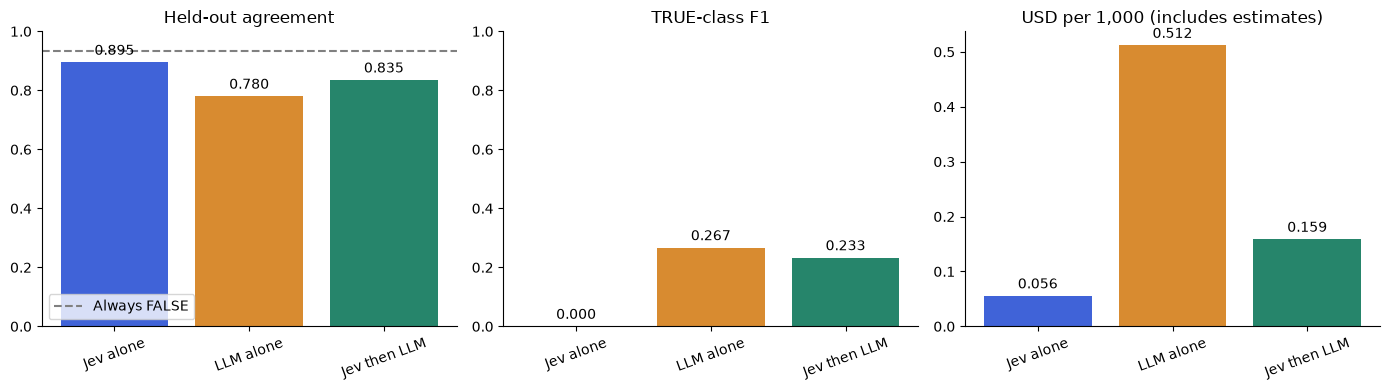

Cascade cost change versus LLM alone (includes estimates): -69.0%
Full benchmark cost including estimates (USD): 0.169953678
Unreported-cost attempts: 600
Estimated-cost attempts: 600
Unknown-cost attempts: 0


In [10]:
plotted = comparison[comparison.method != "Always FALSE"].set_index("method")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ["#4063d8", "#d88b30", "#26856b"]
for ax, field, title in zip(axes, ["accuracy", "f1_TRUE", "cost_per_1000_USD"],
                           ["Held-out agreement", "TRUE-class F1", "USD per 1,000 (includes estimates)"]):
    if field.startswith("cost") and plotted.unknown_cost_attempts.sum():
        ax.text(.5, .5, "Costs incomplete: see table", ha="center")
    else:
        bars = ax.bar(plotted.index, plotted[field], color=colors)
        ax.bar_label(bars, fmt="%.3f", padding=3)
        if field != "cost_per_1000_USD": ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].axhline(comparison.iloc[0].accuracy, color="gray", linestyle="--", label="Always FALSE")
axes[0].legend()
fig.tight_layout()
plt.show()
jev_cost = metrics(heldout, jev_test, "Jev")["cost_usd"]
llm_cost = metrics(heldout, llm_test, "LLM")["cost_usd"]
cascade_cost = metrics(heldout, cascade_test, "Cascade")["cost_usd"]
if not plotted.unknown_cost_attempts.sum() and llm_cost:
    print(f"Cascade cost change versus LLM alone (includes estimates): {(cascade_cost / llm_cost - 1):+.1%}")
else:
    print("Unknown or zero costs: no savings claim.")
all_judges = [*jev_cal.values(), *llm_cal.values(), *jev_test.values(), *llm_test.values()]
print("Full benchmark cost including estimates (USD):", sum(r["cost_usd"] for r in all_judges))
print("Unreported-cost attempts:", sum(r["unreported_cost_attempts"] for r in all_judges))
print("Estimated-cost attempts:", sum(r["estimated_cost_attempts"] for r in all_judges))
print("Unknown-cost attempts:", sum(r["unknown_cost_attempts"] for r in all_judges))

## 8. Why the cascade can work — and when it does not

The cost benefit comes from avoiding LLM calls on accepted Jev judgments. The accuracy
benefit requires something more: low confidence must identify cases worth reviewing,
and the LLM must correct more mistakes than it introduces on that subset. Simply adding
a second judge is not enough. A confidently wrong Jev decision bypasses the LLM; shared
prompt or label problems can confuse both models.

We therefore inspect the kept/escalated groups and count **LLM fixes versus regressions**.
This tests the mechanism instead of assuming confidence predicts accuracy. An LLM can
disagree with the human label and still have a defensible interpretation, so review the
original traces before changing the prompt or labels. Do not tune the threshold on the
held-out results shown below; use a new held-out set after further calibration.

**What the recorded run shows.** The cascade agrees with 83.5% of held-out labels versus
78.0% for LLM alone, at an estimated 69.0% lower cost. It keeps Jev on 161 traces where
Jev agrees with 95.0% of labels versus the LLM's 88.2%. Avoiding those LLM calls explains
the cost reduction and higher agreement relative to LLM alone.

But cascade failure recall is **5/13 (38.5%)**, below the LLM's **8/13 (61.5%)**, and overall
agreement is below Jev alone's 89.5%. On the 39 escalated traces, the LLM fixes six errors
and introduces 18. Low confidence successfully identifies harder traces, but the LLM
is less accurate on them overall. The gate improves rare-failure detection relative to
Jev alone while adding false alarms; it does not improve every metric.

The threshold maximizes the predeclared calibration TRUE-class F1 objective; calibration
has only seven positives and the held-out set only 13. Treat this as a reproducible lesson
in tradeoffs, not evidence that the proposed cascade is ready for production. Review the
rubric and labels on calibration data, then collect a fresh held-out set before iterating.

In [11]:
bands = confidence_bands(heldout, jev_test, llm_test, threshold)
display(pd.DataFrame(bands))
disagreements = []
for r in heldout:
    j, l, c = jev_test[r["id"]], llm_test[r["id"]], cascade_test[r["id"]]
    if j["label"] != l["label"] or c["label"] != r["human_label"]:
        disagreements.append({"ID": r["id"], "query": r["user_query"],
            "candidate_intent": r["predicted_intent"], "human": r["human_label"],
            "Jev": j["label"], "confidence": j.get("confidence"), "LLM": l["label"],
            "final": c["label"], "route": c["route"], "LLM_reason": l.get("reason"),
            "reference_issues": "; ".join(r["reference_issues"])})
display(pd.DataFrame(disagreements).head(12))
pd.DataFrame(disagreements).to_csv(RUN / "disagreements.csv", index=False)
# Show whether cross-file reference inconsistencies materially change the picture.
consistent = [r for r in heldout if not any("differs_between_csvs" in issue
                                           for issue in r["reference_issues"])]
display(pd.DataFrame([metrics(consistent, p, name + " — consistent references")
                      for name, p in [("Jev", jev_test), ("LLM", llm_test), ("Cascade", cascade_test)]]))

,group,n,Jev_accuracy,LLM_accuracy,LLM_fixes,LLM_regressions
0,Kept by Jev,161,0.950311,0.881988,3,14
1,Sent to LLM,39,0.666667,0.358974,6,18


,ID,query,candidate_intent,human,Jev,confidence,LLM,final,route,LLM_reason,reference_issues
0,TEST_031,I am busy today,UNSUPPORTED_REQUEST,TRUE,FALSE,0.60,TRUE,TRUE,LLM,The user's statement 'I am busy today' is ambi...,
1,TEST_032,I'm not working *this* Saturday.,UNBLOCK_SLOTS,FALSE,FALSE,0.72,TRUE,FALSE,Jev,The user states 'I'm not working *this* Saturd...,
2,TEST_034,Free up this weekend,UNBLOCK_SLOTS,FALSE,FALSE,0.82,TRUE,FALSE,Jev,The user query 'Free up this weekend' is ambig...,
3,TEST_040,I can work this monday again,IRRELEVANT_QUERY,TRUE,FALSE,0.30,TRUE,TRUE,LLM,The user's statement 'I can work this Monday a...,
4,TEST_045,I can work this Monday,IRRELEVANT_QUERY,TRUE,FALSE,0.48,TRUE,TRUE,LLM,The user's statement 'I can work this Monday' ...,
5,TEST_085,"I need to block off all of tomorrow, so cancel...",BLOCK_SLOTS,FALSE,FALSE,0.66,TRUE,TRUE,LLM,The user requests to block off all of tomorrow...,
6,TEST_086,Clear my 3 PM,UNSUPPORTED_REQUEST,TRUE,FALSE,0.32,TRUE,TRUE,LLM,The user request 'Clear my 3 PM' is ambiguous ...,
7,TEST_091,"Let's reschedule, I need to block my calendar",UNSUPPORTED_REQUEST,FALSE,TRUE,0.12,TRUE,TRUE,LLM,The user query contains two conflicting reques...,
8,TEST_095,Cancel my 3 PM slot,UNSUPPORTED_REQUEST,TRUE,FALSE,0.76,TRUE,FALSE,Jev,The user request 'Cancel my 3 PM slot' is ambi...,
9,TEST_148,Reserve 10:30 to 11:30 for me tomorrow.,UNSUPPORTED_REQUEST,TRUE,FALSE,0.74,FALSE,FALSE,Jev,The user's request to 'Reserve 10:30 to 11:30 ...,


,method,n,positive_references,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,llm_routes
0,Jev — consistent references,193,13,0.906736,0.000000,0.000000,0.000000,175,5,13,0,0,0.010716,0,0.010716,193,0,193,0
1,LLM — consistent references,193,13,0.803109,0.195122,0.615385,0.296296,147,33,5,8,0,0.098510,0,0.098510,193,0,193,0
2,Cascade — consistent references,193,13,0.854922,0.200000,0.384615,0.263158,160,20,8,5,0,0.029630,0,0.029630,229,0,229,36


## 9. Historical LLM results and reproducibility checks

The original `judge_alignment_1.csv` and `judge_alignment_2.csv` remain available. Their
labels provide historical agreement baselines, but the files do not contain verified
per-request model metadata or token/cost records. We show their agreement without inventing
costs or treating them as controlled comparisons with this run. The fresh benchmark above
is the one that uses identical inputs, one frozen policy, and recorded costs.

In [12]:
historical = []
for filename in ["judge_alignment_1.csv", "judge_alignment_2.csv"]:
    old = pd.read_csv(LAB / "data" / filename, dtype=str, keep_default_na=False)
    lookup = old.set_index("TEST_ID").to_dict("index")
    matching = [r for r in heldout if r["id"] in lookup
                and lookup[r["id"]]["USER_INPUT"] == r["user_query"]
                and lookup[r["id"]]["final_intent"] == r["predicted_intent"]
                and lookup[r["id"]]["Vague_Utterance_Failure"].upper() == r["human_label"]]
    predictions = {r["id"]: {"label": lookup[r["id"]]["LLM_Vague_Utterance_Failure"].upper()}
                   for r in matching}
    m = metrics(matching, predictions, filename)
    m["cost_usd"] = None  # Historical files do not record usage/cost.
    historical.append(m)
display(pd.DataFrame(historical)[["method", "n", "accuracy", "precision_TRUE", "recall_TRUE", "f1_TRUE", "cost_usd"]])

,method,n,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,cost_usd
0,judge_alignment_1.csv,200,0.805,0.117647,0.307692,0.170213,None
1,judge_alignment_2.csv,200,0.865,0.181818,0.307692,0.228571,None


In [13]:
assert len(jev_cal) + len(jev_test) == len(rows)
assert len(llm_cal) + len(llm_test) == len(rows)
assert len(cascade_test) == len(heldout)
assert set(r["id"] for r in calibration).isdisjoint(r["id"] for r in heldout)
if MODE == "replay":
    manifest = json.loads((EVIDENCE / "manifest.json").read_text())
    assert digest(rows) == manifest["dataset_hash"]
    assert digest([POLICY, CRITERIA]) == manifest["policy_hash"]
    assert [r["id"] for r in calibration] == manifest["calibration_ids"]
    assert [r["id"] for r in heldout] == manifest["heldout_ids"]
    assert threshold == manifest["threshold"]
    actual = [metrics(heldout, values, name) for name, values in
              [("Jev alone", jev_test), ("LLM alone", llm_test), ("Jev then LLM", cascade_test)]]
    assert actual == manifest["heldout_metrics"]
    assert client.new_requests == 0
if MODE == "live":
    save_json(RUN / "manifest.json", {
        "dataset_hash": digest(rows), "policy_hash": digest([POLICY, CRITERIA]),
        "calibration_ids": [r["id"] for r in calibration],
        "heldout_ids": [r["id"] for r in heldout], "threshold": threshold,
        **client.configuration(),
        "heldout_metrics": [metrics(heldout, values, name) for name, values in
                            [("Jev alone", jev_test), ("LLM alone", llm_test), ("Jev then LLM", cascade_test)]]})
    print("Replay this run by setting JUDGE_MODE=replay and JUDGE_EVIDENCE_DIR to", RUN)
save_json(RUN / "summary.json", {"mode": MODE, "threshold": threshold,
    "dataset_hash": digest(rows), "comparison": comparison.to_dict("records"),
    "bands": bands, "new_http_attempts": client.new_requests})
print("Notebook completed. Fresh HTTP attempts:", client.new_requests)
print("Outputs:", RUN)
print("Unresolved rows:", comparison.set_index("method")["unresolved"].to_dict())

Notebook completed. Fresh HTTP attempts: 0
Outputs: routing_agent_evals/.runs/judge
Unresolved rows: {'Always FALSE': 0, 'Jev alone': 0, 'LLM alone': 0, 'Jev then LLM': 0}


## Take this into your own eval loop

Keep an explicit human rubric, a calibration set, and an untouched test set. Inspect rare
failure recall and high-confidence errors, not just aggregate accuracy. Choose the gate
for the product's cost of false alarms and missed failures. Recheck after model, prompt,
data, or pricing changes. Low-confidence fallback can improve cost and quality together,
but this notebook's measurements determine whether that happened on these traces.

To make a fresh run, select `live`, use a TypeSafe key for Jev and a funded OpenAI (or OpenRouter) key for the LLM, and choose a new
`JUDGE_RUN_DIR`. To replay that run, set `JUDGE_MODE=replay` and
`JUDGE_EVIDENCE_DIR` to the same directory. Changing the model or prompt changes the request hash, so stale cache
entries cannot silently supply results for a different experiment. Unit tests:
`python -m pytest tests -q` from this directory.